Simulating hodgkin huxley neurons in C++
This is just a quick bit of testing, but may provide a base for an improved version of the simulator

Basic features:
Single compartment conductance based neurons
Voltage and ligand gating 
Simple conductance based synapses

Conductance based neurons:
Resting membrane potential defined in terms of membrane conductances for each ion # Nernst potentials for Na, K, Cl, and Ca, and 
Monoexponential gating defined in terms of Vhalf, Vk, theta0 theta1 sig0 k0



Extra features:
Multicompartments
ChatGPT compile python to c++
Delays
Gap junctions 
Short term plasticity
Long term calcium based plasticity 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

invCap = 1/1
TS = 0.1
runTime = 20
ions = ["Na","K","Cl","Ca"]
nIons = len(ions)
nNeurons = 5
voltages = np.ones([nNeurons],dtype = np.float32)
voltages[0],voltages[1] = -20.0,-60.0
membraneConductances = np.zeros([nNeurons,nIons])
membraneConductances[:,0] = 0.05
membraneConductances[:,1] = 0.3
membraneConductances[:,2] = 0.3
membraneConductances[:,3] = 0

nernstPotentials = np.zeros([nNeurons,nIons],dtype=np.float32)
nernstPotentials[:,0] = 60.0
nernstPotentials[:,1] = -90.0
nernstPotentials[:,2] = -80.0
nernstPotentials[:,3] = 120

nIterations = int(runTime/TS)

vOverTime = []
for i in range(nIterations):
    netCurrent = np.zeros(nNeurons)
    for i in range(nNeurons):
        for j in range(nIons):
            netCurrent[i] += membraneConductances[i,j]*(voltages[i]-nernstPotentials[i,j])

    voltages += -invCap*TS*netCurrent
    vOverTime.append(voltages.copy())

vOverTime = np.array(vOverTime)
voltages

array([-73.84608, -73.8461 , -73.84604, -73.84604, -73.84604],
      dtype=float32)

In [ ]:
#need to map gates to ion channels to neurons
#although if we assume 2 gates per neuron, we can just map gates to neuron 

Vhalf = []
ks = []
taus = []
ions = []
conductances = []

def addChannelToNeuron(ionChannelInfo,Vhalf,Ks,taus,ions,conductances,ionList):
    vhs = [ionChannelInfo["gate1"]["Vhalf"],ionChannelInfo["gate2"]["Vhalf"]]
    vks = [ionChannelInfo["gate1"]["Vk"],ionChannelInfo["gate2"]["Vk"]] 
    thetas = [ionChannelInfo["gate1"]["theta"],ionChannelInfo["gate2"]["theta"]] 
    ion = ionList.index(ionChannelInfo["ion"])
    cond = ionChannelInfo["conductance"]
    Vhalf.append(vhs)
    Ks.append(vks)
    taus.append(thetas)
    ions.append(ion)
    conductances.append(cond)
    

gate1 = {"Vhalf":-40,
         "Vk": 2,
         "theta": 10}

gate2 = {"Vhalf":-35,
         "Vk":2,
         "theta": 1}

channel = {"ion":"Na",
           "conductance": 10,
           "gate1":gate1,
           "gate2":gate2}




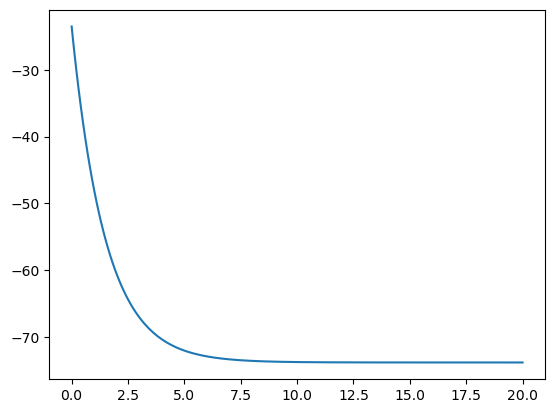

In [2]:
tV = np.linspace(0,runTime,len(vOverTime))
plt.plot(tV,vOverTime[:,0])

In [48]:
vOverTime = np.array(vOverTime)


[[-51.5, -71.0, -41.26250076293945, -41.26250076293945, -41.26250076293945],
 [-66.85624694824219,
  -76.36250305175781,
  -61.86547088623047,
  -61.86547088623047,
  -61.86547088623047],
 [-74.34242248535156,
  -78.97672271728516,
  -71.90941619873047,
  -71.90941619873047,
  -71.90941619873047],
 [-77.99192810058594,
  -80.25115203857422,
  -76.80583953857422,
  -76.80583953857422,
  -76.80583953857422],
 [-79.77106475830078,
  -80.8724365234375,
  -79.1928482055664,
  -79.1928482055664,
  -79.1928482055664],
 [-80.63839721679688,
  -81.1753158569336,
  -80.35651397705078,
  -80.35651397705078,
  -80.35651397705078],
 [-81.06121826171875,
  -81.32296752929688,
  -80.92379760742188,
  -80.92379760742188,
  -80.92379760742188],
 [-81.26734161376953,
  -81.39494323730469,
  -81.20034790039062,
  -81.20034790039062,
  -81.20034790039062],
 [-81.36782836914062,
  -81.43003845214844,
  -81.33516693115234,
  -81.33516693115234,
  -81.33516693115234],
 [-81.41681671142578,
  -81.447143554687

In [9]:
voltages.repeat(nIons,axis=1) - nernstPotentials

AxisError: axis 1 is out of bounds for array of dimension 1